# Claims reserving from first principles

**Question:** how much money must an insurer set aside today for claims that have already happened but are not yet fully paid?

This notebook walks through three classic answers on the Taylor & Ashe triangle (the example in Mack, 1993):

1. **Chain-ladder** - the point estimate
2. **Mack** - how uncertain that estimate is
3. **Bornhuetter-Ferguson / Cape Cod** - blending the data with a prior expectation

Every method is implemented in `src/reserving/` and tested against the published numbers.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import matplotlib.pyplot as plt
from reserving import ChainLadder, MackChainLadder, CapeCod, to_incremental
from reserving.datasets import genins
from reserving.plotting import plot_development, plot_reserves, plot_residuals

pd.options.display.float_format = "{:,.0f}".format

## 1. The data: a run-off triangle

Rows are **origin (accident) years**, columns are **development lags**. Each cell is the cumulative amount paid for claims of that origin year by the end of that lag. The lower right is the future - that is what we need to estimate.

In [2]:
tri = genins()
tri

dev,1,2,3,4,5,6,7,8,9,10
origin,,,,,,,,,,
1,"357,848","1,124,788","1,735,330","2,218,270","2,745,596","3,319,994","3,466,336","3,606,286","3,833,515","3,901,463"
2,"352,118","1,236,139","2,170,033","3,353,322","3,799,067","4,120,063","4,647,867","4,914,039","5,339,085",NaN
3,"290,507","1,292,306","2,218,525","3,235,179","3,985,995","4,132,918","4,628,910","4,909,315",NaN,NaN
4,"310,608","1,418,858","2,195,047","3,757,447","4,029,929","4,381,982","4,588,268",NaN,NaN,NaN
5,"443,160","1,136,350","2,128,333","2,897,821","3,402,672","3,873,311",NaN,NaN,NaN,NaN
6,"396,132","1,333,217","2,180,715","2,985,752","3,691,712",NaN,NaN,NaN,NaN,NaN
7,"440,832","1,288,463","2,419,861","3,483,130",NaN,NaN,NaN,NaN,NaN,NaN
8,"359,480","1,421,128","2,864,498",NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,"376,686","1,363,294",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


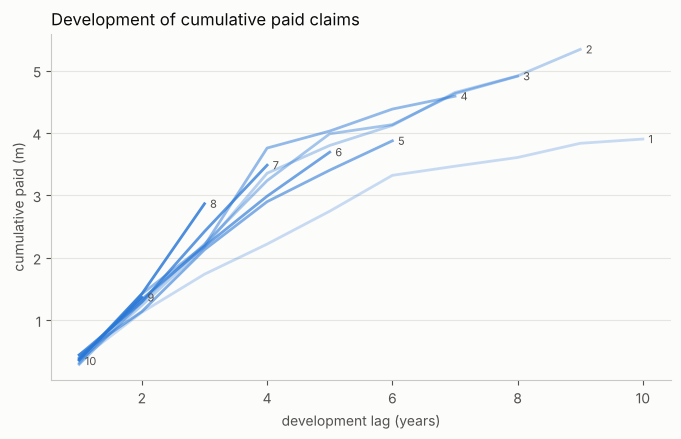

In [3]:
ax = plot_development(tri)
plt.show()

Payments grow quickly in the first years and flatten out later. The chain-ladder idea: **younger years will develop the same way older years did.**

## 2. Chain-ladder

The volume-weighted development factor from lag $k$ to $k+1$ is

$$\hat f_k = \frac{\sum_i C_{i,k+1}}{\sum_i C_{i,k}}$$

summed over all origins where both cells are known. Multiplying the latest diagonal by the remaining factors gives the ultimate.

In [4]:
cl = ChainLadder().fit(tri)
cl.ldf_.to_frame().T.style.format("{:.3f}")

,1-2,2-3,3-4,4-5,5-6,6-7,7-8,8-9,9-10
ldf,3.491,1.747,1.457,1.174,1.104,1.086,1.054,1.077,1.018


In [5]:
cl.summary().style.format({"latest": "{:,.0f}", "cdf": "{:.3f}", "ultimate": "{:,.0f}", "reserve": "{:,.0f}"})

,latest,cdf,ultimate,reserve
origin,,,,
1,"3,901,463",1.000,"3,901,463",0
2,"5,339,085",1.018,"5,433,719","94,634"
3,"4,909,315",1.096,"5,378,826","469,511"
4,"4,588,268",1.155,"5,297,906","709,638"
5,"3,873,311",1.254,"4,858,200","984,889"
6,"3,691,712",1.384,"5,111,171","1,419,459"
7,"3,483,130",1.625,"5,660,771","2,177,641"
8,"2,864,498",2.369,"6,784,799","3,920,301"
9,"1,363,294",4.139,"5,642,266","4,278,972"


In [6]:
print(f"Total chain-ladder reserve: {cl.reserve_.sum():,.0f}")

Total chain-ladder reserve: 18,680,856


## 3. Mack: how wrong could we be?

Mack (1993) assumes

$$E[C_{i,k+1} \mid C_{i,k}] = f_k C_{i,k}, \qquad \operatorname{Var}[C_{i,k+1} \mid C_{i,k}] = \sigma_k^2 C_{i,k}$$

and independent origin years. Under these assumptions $\hat f_k$ is unbiased, and the mean squared error of the reserve splits into
- **process error** - randomness of future payments, and
- **parameter error** - we only *estimated* the factors.

The total standard error also includes covariances, because every origin year uses the same estimated factors.

In [7]:
mack = MackChainLadder().fit(tri)
summary = mack.summary()
summary["process_se"] = mack.process_se_
summary["parameter_se"] = mack.parameter_se_
summary.style.format({"cv": "{:.0%}"}, na_rep="-").format("{:,.0f}", subset=["latest", "ultimate", "reserve", "mack_se", "process_se", "parameter_se"])

,latest,ultimate,reserve,mack_se,cv,process_se,parameter_se
origin,,,,,,,
1,"3,901,463","3,901,463",0,0,-,0,0
2,"5,339,085","5,433,719","94,634","75,535",80%,"48,832","57,628"
3,"4,909,315","5,378,826","469,511","121,699",26%,"90,524","81,338"
4,"4,588,268","5,297,906","709,638","133,549",19%,"102,622","85,464"
5,"3,873,311","4,858,200","984,889","261,406",27%,"227,880","128,078"
6,"3,691,712","5,111,171","1,419,459","411,010",29%,"366,582","185,867"
7,"3,483,130","5,660,771","2,177,641","558,317",26%,"500,202","248,023"
8,"2,864,498","6,784,799","3,920,301","875,328",22%,"785,741","385,759"
9,"1,363,294","5,642,266","4,278,972","971,258",23%,"895,570","375,893"


In [8]:
print(f"Total reserve : {mack.total_reserve_:,.0f}")
print(f"Total Mack SE : {mack.total_mack_se_:,.0f}  ({mack.total_mack_se_ / mack.total_reserve_:.0%} of the reserve)")
print("Published in Mack (1993): 18,680,856 and 2,447,095")

Total reserve : 18,680,856
Total Mack SE : 2,447,095  (13% of the reserve)
Published in Mack (1993): 18,680,856 and 2,447,095


The youngest year has a coefficient of variation near 30%: one cell of data has to carry nine development steps.

### Checking the assumptions

If the model fits, the weighted residuals $(C_{i,k+1} - \hat f_k C_{i,k}) / \sqrt{\hat\sigma_k^2 C_{i,k}}$ should show no pattern against origin, lag or calendar period. A trend over **calendar periods** would point to inflation or a change in claims handling - something chain-ladder cannot capture.

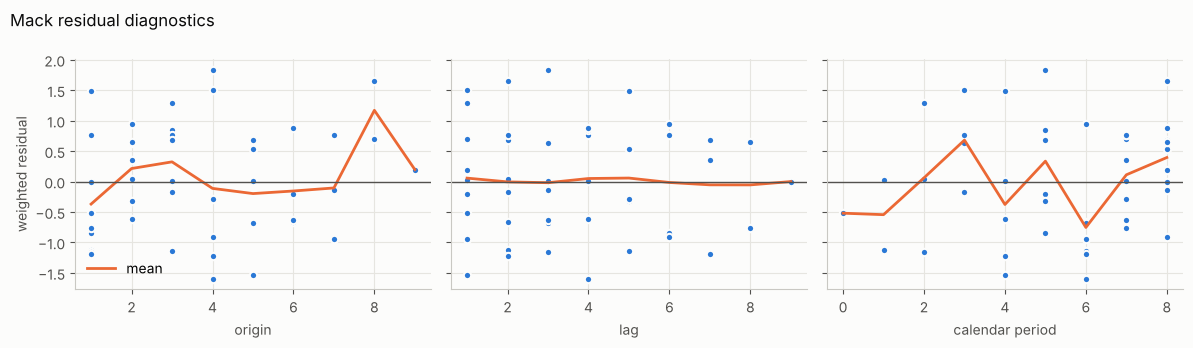

In [9]:
axes = plot_residuals(mack.residuals(tri))
plt.tight_layout()
plt.show()

## 4. Bornhuetter-Ferguson and Cape Cod

Chain-ladder trusts the latest diagonal completely. For the youngest year that is one number, so a single unusual payment moves the whole estimate.

Bornhuetter-Ferguson instead takes the **expected** ultimate from premium x expected loss ratio (ELR) and only uses the development pattern to say how much of it is still to come:

$$R_i^{BF} = P_i \cdot \text{ELR} \cdot \left(1 - \frac{1}{CDF_i}\right)$$

This is a credibility weighting: the weight on the data is $1/CDF_i$, which is close to 1 for old years and small for young ones.

**Cape Cod** estimates the ELR from the triangle itself, so the prior uses no outside information. Taylor & Ashe publish no premium, so a flat illustrative premium is used here.

In [10]:
premium = pd.Series(8e6, index=tri.index)
cc = CapeCod().fit(tri, premium)
print(f"Cape Cod ELR: {cc.elr:.1%}")

compare = pd.DataFrame({
    "chain_ladder": cl.reserve_,
    "cape_cod": cc.reserve_,
    "weight_on_data": cc.credibility_,
})
compare.style.format({"chain_ladder": "{:,.0f}", "cape_cod": "{:,.0f}", "weight_on_data": "{:.0%}"})

Cape Cod ELR: 64.8%


,chain_ladder,cape_cod,weight_on_data
origin,,,
1,0,0,100%
2,"94,634","90,264",98%
3,"469,511","452,401",91%
4,"709,638","694,220",87%
5,"984,889","1,050,694",80%
6,"1,419,459","1,439,352",72%
7,"2,177,641","1,993,771",62%
8,"3,920,301","2,994,657",42%
9,"4,278,972","3,930,524",24%


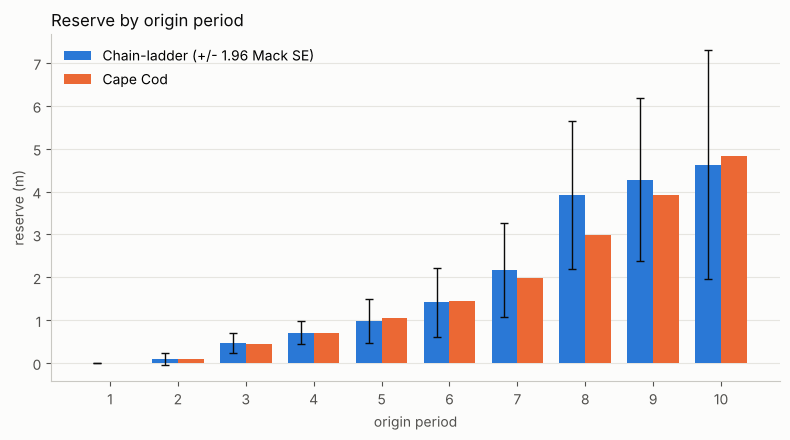

In [11]:
ax = plot_reserves(mack, cc)
plt.tight_layout()
plt.show()

For origin year 8 chain-ladder is well above Cape Cod: its lag-3 value is unusually high (visible in the development plot), and chain-ladder projects that forward. Cape Cod gives that single observation less weight.

## 5. Next step: does any of this work on real data?

A method that reproduces a textbook is not yet a method that predicts well. The CAS Schedule P database contains the **actual** later development of hundreds of US insurers, so the estimates can be checked against reality:

```bash
python scripts/download_cas_data.py
python scripts/run_backtest.py
```

See the README for the results and their interpretation.